In [1]:
import pandas as pd

train = pd.read_csv('train_set.csv')
test = pd.read_csv('test_set.csv')
full = pd.read_csv('preprocessed_dataset.csv')

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Full shape:", full.shape)

print("\n--- Train columns ---")
print(train.columns.tolist())

print("\n--- First 5 rows of train ---")
print(train.head())

Train shape: (5634, 11)
Test shape: (1409, 11)
Full shape: (7043, 11)

--- Train columns ---
['gender', 'SeniorCitizen', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'MonthlyCharges', 'Contract_One_year', 'Contract_Two_year', 'Churn']

--- First 5 rows of train ---
   gender  SeniorCitizen  Dependents    tenure  PhoneService  MultipleLines  \
0       1              0           1 -1.276682             1              0   
1       0              0           0 -0.096089             1              0   
2       0              1           0  0.555273             1              1   
3       1              0           0  0.433143             1              0   
4       1              0           0 -1.276682             1              1   

   InternetService  MonthlyCharges  Contract_One_year  Contract_Two_year  \
0                0       -0.149881                  0                  1   
1                0       -0.315125                  1                  0   


In [2]:
print("--- Churn distribution in train ---")
print(train['Churn'].value_counts())
print("\nChurn % in train:")
print(train['Churn'].value_counts(normalize=True) * 100)

print("\n--- Churn distribution in test ---")
print(test['Churn'].value_counts())
print("\nChurn % in test:")
print(test['Churn'].value_counts(normalize=True) * 100)

print("\n--- Missing values in train ---")
print(train.isnull().sum())
print("\n--- Missing values in test ---")
print(test.isnull().sum())

print("\n--- Data types in train ---")
print(train.dtypes)

--- Churn distribution in train ---
Churn
0    4139
1    1495
Name: count, dtype: int64

Churn % in train:
Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

--- Churn distribution in test ---
Churn
0    1035
1     374
Name: count, dtype: int64

Churn % in test:
Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64

--- Missing values in train ---
gender               0
SeniorCitizen        0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
MonthlyCharges       0
Contract_One_year    0
Contract_Two_year    0
Churn                0
dtype: int64

--- Missing values in test ---
gender               0
SeniorCitizen        0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
MonthlyCharges       0
Contract_One_year    0
Contract_Two_year    0
Churn                0
dtype: int64

--- Data types in train ---
gender                 

In [3]:
# Step 7: Build the ANN model

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.utils.class_weight import compute_class_weight

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Split features (X) and target (y)
X_train = train.drop('Churn', axis=1).values
y_train = train['Churn'].values
X_test  = test.drop('Churn', axis=1).values
y_test  = test['Churn'].values

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test: ", X_test.shape, "| y_test: ", y_test.shape)

# Compute class weights to handle the 73/27 imbalance
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print("\nClass weights:", class_weight_dict)

# Build the ANN (matches the architecture we agreed)
model = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation='relu', name='hidden_1'),
    layers.Dropout(0.3, name='dropout_1'),
    layers.Dense(8, activation='relu', name='hidden_2'),
    layers.Dense(1, activation='sigmoid', name='output')
])

# Compile
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Show the architecture summary
model.summary()

X_train: (5634, 10) | y_train: (5634,)
X_test:  (1409, 10) | y_test:  (1409,)

Class weights: {0: np.float64(0.6805991785455424), 1: np.float64(1.8842809364548494)}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 16)             │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Step 8: Train the ANN with early stopping

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5090 - loss: 0.6763 - val_accuracy: 0.5847 - val_loss: 0.6737
Epoch 2/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6119 - loss: 0.6141 - val_accuracy: 0.6788 - val_loss: 0.5897
Epoch 3/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6854 - loss: 0.5727 - val_accuracy: 0.7143 - val_loss: 0.5506
Epoch 4/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6954 - loss: 0.5650 - val_accuracy: 0.7249 - val_loss: 0.5359
Epoch 5/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7156 - loss: 0.5533 - val_accuracy: 0.7214 - val_loss: 0.5319
Epoch 6/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7227 - loss: 0.5435 - val_accuracy: 0.7214 - val_loss: 0.5253
Epoch 7/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7160 - loss: 0.5457 - val_accuracy: 0.7267 - val_loss: 0.5242
Epoch 8/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7178 - loss: 0.5445 - val_accuracy: 0.

In [5]:
# Step 9: Evaluate on the held-out test set

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_auc_score)

# Predict probabilities, then convert to 0/1 using 0.5 threshold
y_pred_prob = model.predict(X_test).ravel()
y_pred = (y_pred_prob >= 0.5).astype(int)

print("--- Test set performance (threshold = 0.5) ---")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_pred_prob):.4f}")

print("\n--- Confusion matrix ---")
print(confusion_matrix(y_test, y_pred))

print("\n--- Full classification report ---")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
--- Test set performance (threshold = 0.5) ---
Accuracy : 0.7232
Precision: 0.4859
Recall   : 0.7380
F1-score : 0.5860
ROC-AUC  : 0.8085

--- Confusion matrix ---
[[743 292]
 [ 98 276]]

--- Full classification report ---
              precision    recall  f1-score   support

    No Churn       0.88      0.72      0.79      1035
       Churn       0.49      0.74      0.59       374

    accuracy                           0.72      1409
   macro avg       0.68      0.73      0.69      1409
weighted avg       0.78      0.72      0.74      1409



Saved: ann_churn_model.keras


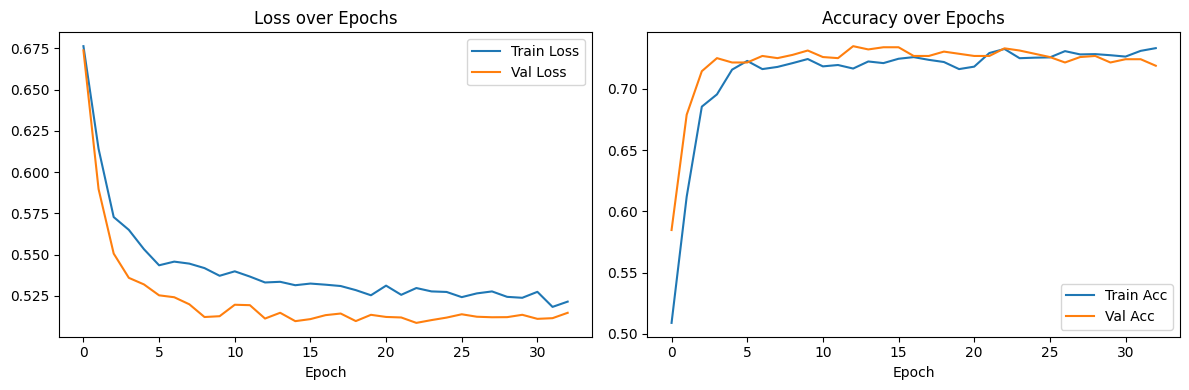

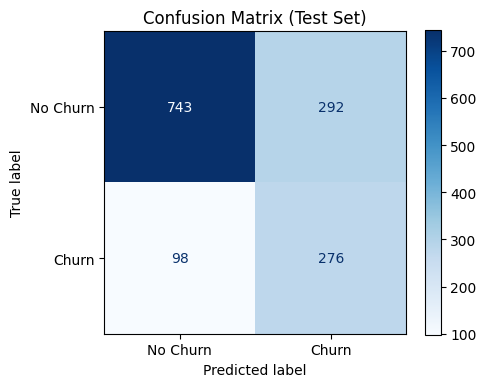

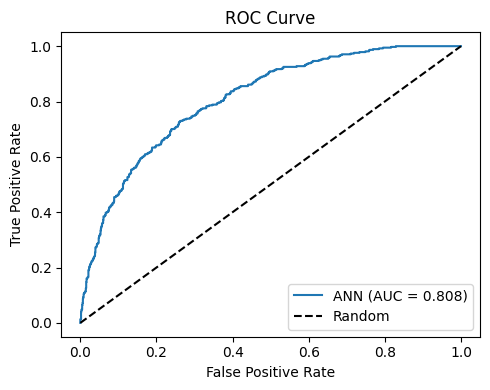


Metrics saved:
               Metric   Value
0           Accuracy  0.7232
1  Precision (Churn)  0.4859
2     Recall (Churn)  0.7380
3         F1 (Churn)  0.5860
4            ROC-AUC  0.8085

Saved: test_predictions.csv

All outputs written to ann_outputs/


In [6]:
# Step 10: Save model, plots, metrics, predictions

import os
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

os.makedirs('ann_outputs', exist_ok=True)

# 1. Save the trained model
model.save('ann_outputs/ann_churn_model.keras')
print("Saved: ann_churn_model.keras")

# 2. Training history plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Loss over Epochs'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(history.history['accuracy'], label='Train Acc')
axes[1].plot(history.history['val_accuracy'], label='Val Acc')
axes[1].set_title('Accuracy over Epochs'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout()
plt.savefig('ann_outputs/training_history.png', dpi=150)
plt.show()

# 3. Confusion matrix plot
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
    display_labels=['No Churn', 'Churn'], cmap='Blues', ax=ax)
plt.title('Confusion Matrix (Test Set)')
plt.tight_layout()
plt.savefig('ann_outputs/confusion_matrix.png', dpi=150)
plt.show()

# 4. ROC curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
auc = roc_auc_score(y_test, y_pred_prob)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f'ANN (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve'); plt.legend()
plt.tight_layout()
plt.savefig('ann_outputs/roc_curve.png', dpi=150)
plt.show()

# 5. Metrics table
import pandas as pd
metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Churn)', 'Recall (Churn)',
               'F1 (Churn)', 'ROC-AUC'],
    'Value': [
        round(accuracy_score(y_test, y_pred), 4),
        round(precision_score(y_test, y_pred), 4),
        round(recall_score(y_test, y_pred), 4),
        round(f1_score(y_test, y_pred), 4),
        round(roc_auc_score(y_test, y_pred_prob), 4),
    ]
})
metrics_df.to_csv('ann_outputs/metrics.csv', index=False)
print("\nMetrics saved:\n", metrics_df)

# 6. Save predictions
pred_df = test.copy()
pred_df['Churn_Probability'] = y_pred_prob
pred_df['Churn_Predicted'] = y_pred
pred_df.to_csv('ann_outputs/test_predictions.csv', index=False)
print("\nSaved: test_predictions.csv")

print("\nAll outputs written to ann_outputs/")